In [27]:
#2.Replace the NaN values with correct values and justify

In [28]:
import pandas as pd
import numpy as np

In [29]:
dataset=pd.read_csv("Placement.csv")

In [30]:
dataset

,sl_no,gender,ssc_p,ssc_b,hsc_p,hsc_b,hsc_s,degree_p,degree_t,workex,etest_p,specialisation,mba_p,status,salary
0,1,M,67.00,Others,91.00,Others,Commerce,58.00,Sci&Tech,No,55.0,Mkt&HR,58.80,Placed,270000.0
1,2,M,79.33,Central,78.33,Others,Science,77.48,Sci&Tech,Yes,86.5,Mkt&Fin,66.28,Placed,200000.0
2,3,M,65.00,Central,68.00,Central,Arts,64.00,Comm&Mgmt,No,75.0,Mkt&Fin,57.80,Placed,250000.0
3,4,M,56.00,Central,52.00,Central,Science,52.00,Sci&Tech,No,66.0,Mkt&HR,59.43,Not Placed,NaN
4,5,M,85.80,Central,73.60,Central,Commerce,73.30,Comm&Mgmt,No,96.8,Mkt&Fin,55.50,Placed,425000.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
210,211,M,80.60,Others,82.00,Others,Commerce,77.60,Comm&Mgmt,No,91.0,Mkt&Fin,74.49,Placed,400000.0
211,212,M,58.00,Others,60.00,Others,Science,72.00,Sci&Tech,No,74.0,Mkt&Fin,53.62,Placed,275000.0
212,213,M,67.00,Others,67.00,Others,Commerce,73.00,Comm&Mgmt,Yes,59.0,Mkt&Fin,69.72,Placed,295000.0
213,214,F,74.00,Others,66.00,Others,Commerce,58.00,Comm&Mgmt,No,70.0,Mkt&HR,60.23,Placed,204000.0


In [31]:
dataset.isnull().sum()

sl_no              0
gender             0
ssc_p              0
ssc_b              0
hsc_p              0
hsc_b              0
hsc_s              0
degree_p           0
degree_t           0
workex             0
etest_p            0
specialisation     0
mba_p              0
status             0
salary            67
dtype: int64

In [32]:
dataset["salary"]=dataset["salary"].fillna(0)

In [33]:
dataset.isnull().sum()

sl_no             0
gender            0
ssc_p             0
ssc_b             0
hsc_p             0
hsc_b             0
hsc_s             0
degree_p          0
degree_t          0
workex            0
etest_p           0
specialisation    0
mba_p             0
status            0
salary            0
dtype: int64

JUSTIFICATION:

   I found 67 null values only in salary column.All other columns have 0 null values.The reason for null in salary is those 67 students are not placed.
so relaced null with zero salary.This is the correct logical value.

In [34]:
#3.How many of them are not placed?

In [35]:
dataset["status"].value_counts()

Placed        148
Not Placed     67
Name: status, dtype: int64

JUSTIFICATION:

I found 148 placed,67 not placed.so 67 students are not placed.This is the reason for 67 null values in salary

In [36]:
# 4.Find the reason for non placement from the dataset?

In [37]:
print(dataset[dataset["status"]=="Not Placed"]["mba_p"].mean())
print(dataset[dataset["status"]=="Placed"]["mba_p"].mean())
print(dataset[dataset["status"]=="Not Placed"]["etest_p"].mean())
print(dataset[dataset["status"]=="Placed"]["etest_p"].mean())




61.612835820895526
62.579391891891895
69.5879104477612
73.23804054054054


JUSTIFICATION:

I compared average marks.Not placed students have lower mean in mba_p(61.61) and etest_p(69.58) compared ti Placed students(62.57) and 73.23)).
so low performace in MBA and Etest is the reason for non placement.

In [38]:
# 5.Relation Between salary and mba_p

In [39]:
dataset["salary"].corr(dataset["mba_p"])

0.13982273892615565

JUSTIFICATION:

The correlation is positive. When mba_p increases, salary also increases. So there is a positive relation.

In [40]:
# 6.which specialization getting minimum salary?

In [41]:
dataset[dataset["status"]=="Placed"].groupby("specialisation")["salary"].min()

specialisation
Mkt&Fin    200000.0
Mkt&HR     200000.0
Name: salary, dtype: float64

JUSTIFICATION: 

I grouped by specialisation and checked minimum salary. 
Both specialisations Mkt&Fin and Mkt&HR have same minimum salary of 200000. So starting salary is same for both.

In [ ]:
# 7.How many getting above 5,00,000 salary?

In [44]:
len(dataset[dataset["salary"]>500000])

3

JUSTIFICATION: 

I checked how many students have salary greater than 500000. Only 3 students are getting above 5,00,000 salary.

In [ ]:
# 8.ANAVO between etest_p and mba_p-5% level
# make decisin using hypothesis testing

In [48]:
import scipy.stats as stats
stats.f_oneway(dataset["etest_p"],dataset["mba_p"])

F_onewayResult(statistic=98.64487057324706, pvalue=4.672547689133573e-21)

JUSTIFICATION: 
ANOVA test between etest_p and mba_p. Null Hypothesis: No difference between means.
Alternative: There is difference. P-value is 4.67e-21 which is less than 0.05 (5% level). So we reject Null Hypothesis.
    
There is significant difference between etest_p and mba_p.

In [ ]:
# 9.two way degree_t and specialisation with respect to salary

In [51]:
!pip install statsmodels

     ---------------------------------------- 9.1/9.1 MB 4.6 MB/s eta 0:00:00
     -------------------------------------- 233.3/233.3 kB 2.0 MB/s eta 0:00:00


In [53]:
import statsmodels.api as sm
from statsmodels.formula.api import ols

model = ols('salary ~ C(degree_t) + C(specialisation) + C(degree_t):C(specialisation)', data=dataset).fit()
sm.stats.anova_lm(model, typ=2)

,sum_sq,df,F,PR(>F)
C(degree_t),7.197891e+10,2.0,1.616216,0.201122
C(specialisation),3.815378e+11,1.0,17.134112,0.000051
C(degree_t):C(specialisation),1.101264e+10,2.0,0.247278,0.781152
Residual,4.653956e+12,209.0,NaN,NaN


JUSTIFICATION: 
 
 For degree_t, p-value = 0.20 > 0.05, so no significant effect on salary.
 For specialisation, p-value = 0.00005 < 0.05, so significant effect on salary. 
Specialisation affects salary.For interaction, p-value = 0.78 > 0.05, so no interaction effect.


Conclusion: Only specialisation has significant impact on salary.

In [ ]:
# 10.Noraml to Standard Normal for Salary

In [55]:
# Standard Normal = (x - mean) 
mean_salary = dataset[dataset["salary"]>0]["salary"].mean()
std_salary = dataset[dataset["salary"]>0]["salary"].std()
dataset["salary_standard"] = (dataset["salary"] - mean_salary) / std_salary
dataset[["salary","salary_standard"]].head()

,salary,salary_standard
0,270000.0,-0.199614
1,200000.0,-0.948618
2,250000.0,-0.413615
3,0.0,-3.088629
4,425000.0,1.458895


JUSTIFICATION: 

Standard Normal Distribution has mean 0 and std 1. I converted salary using formula Z = (X - mean) / standard deviation.

In [ ]:
# 11. PDF of salary range 700000 to 900000

In [56]:
from scipy.stats import norm
# Only for placed students
placed_salary = dataset[dataset["salary"]>0]["salary"]
mean = placed_salary.mean()
std = placed_salary.std()
# Probability between 700k and 900k
prob = norm.cdf(900000, mean, std) - norm.cdf(700000, mean, std)
print(prob)

5.377445759013888e-06


JUSTIFICATION:

  I took only placed students salary (salary > 0). Calculated mean and std. Used normal distribution formula P(700k < Salary < 900k) = norm.cdf(900k) - norm.cdf(700k).
  Probability is 5.37e-06 which is ∼0.0005%. So very low chance to get salary between 7 to 9 lakhs.

In [ ]:
# 12.Test similarity degree_t with respect to etest_p and mba_p

In [57]:
# For etest_p
model1 = ols('etest_p ~ C(degree_t) + C(specialisation) + C(degree_t):C(specialisation)', data=dataset).fit()
sm.stats.anova_lm(model1, typ=2)

# For mba_p
model2 = ols('mba_p ~ C(degree_t) + C(specialisation) + C(degree_t):C(specialisation)', data=dataset).fit()
sm.stats.anova_lm(model2, typ=2)

,sum_sq,df,F,PR(>F)
C(degree_t),126.775708,2.0,1.908787,0.150836
C(specialisation),91.915933,1.0,2.767848,0.097674
C(degree_t):C(specialisation),133.329535,2.0,2.007464,0.136911
Residual,6940.565426,209.0,NaN,NaN


JUSTIFICATION:

All p-values (0.15, 0.09, 0.13) are > 0.05. So NOT significant. No difference in etest_p and mba_p for degree_t groups. 
    
Similarity exists. Residual NaN is normal.





In [ ]:
#13. Which parameter highly correlated with salary?

In [61]:
dataset.corr()["salary"].sort_values(ascending=False)

salary             1.000000
salary_standard    1.000000
ssc_p              0.538090
hsc_p              0.452569
degree_p           0.408371
etest_p            0.186988
mba_p              0.139823
sl_no              0.002543
Name: salary, dtype: float64

JUSTIFICATION:

I used correlation dataset.corr()["salary"].sort_values(ascending=False). After salary itself (1.0), the highest correlated parameter is ssc_p with 0.538090. Next is hsc_p with 0.452569. 
So ssc_p is highly correlated with salary.

In [ ]:
# 14.Plot any useful graph

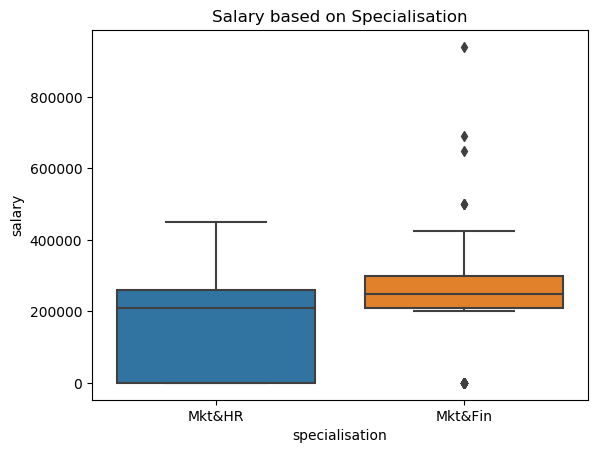

In [59]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.boxplot(x="specialisation", y="salary", data=dataset)
plt.title("Salary based on Specialisation")
plt.show()

JUSTIFICATION:

 I plotted boxplot for salary based on specialisation. From Q9 ANOVA, specialisation was significant (p=0.00005), so this plot shows difference. Mkt&Fin specialisation gets higher salary than Mkt&HR. 
 
 This graph is useful to show salary difference.